<a href="https://colab.research.google.com/github/gabrielelim/DATA_PREPROCESSING/blob/main/Copy_of_running_the_model_workshop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Running the model

This notebook assembles one forecast from the raw forecast files, runs the trained ConvCNP on it, compares the prediction with CHIRTS-ERA5 and with the raw forecasts, and ends with a sketch of the training loop.
It uses a small cut of the data for Mali and Kenya, so that everything runs in Google Colab.

Run the cells from top to bottom.
The first cell installs the required packages and downloads the data.
The Utilities section is technical and can be skipped on a first read.
Look out for the **Try it** boxes, which ask you to change a setting and run everything again with *Runtime → Run all*.

> **Before you start**
>
> 1. **Save your own copy:** *File → Save a copy in Drive*. This needs a Google account. Your copy opens in a new tab; work in that one. Your changes are then saved in your own Google Drive, and nobody else's copy is affected.
> 2. **"Warning: This notebook was not authored by Google"** appears when you run the first cell. This is normal for any notebook that Google didn't write. Click **Run anyway**. The notebook only installs packages and downloads the workshop data.
> 3. **Files you create** (like `results.csv`) are deleted when the Colab session ends. Download them from the *Files* panel on the left if you want to keep them.

## Setup

In [ ]:
import subprocess
import sys
import zipfile
from pathlib import Path

# The data and the demographics on Google Drive. Both unzip into `workshop_data`.
ZIPS = {
    "heatews_running_the_model_workshop.zip": "1DhRfWUI8_7uX-1JLSv8YmnOn4ZrtdTfv",
    "heatews_demographics_2025.zip": "1Mmdc5FZJwL4x5tI1pkTC2LuWONgDzcYI",
}

# In Colab, install the missing packages and download the data if it is not there yet.
if "google.colab" in sys.modules:
    pip = [sys.executable, "-m", "pip", "install", "-q"]
    subprocess.run(pip + ["cartopy", "netCDF4", "gdown"], check=True)
    import gdown

    if not Path("workshop_data").exists():
        for name, file_id in ZIPS.items():
            gdown.download(id=file_id, output=name)
            with zipfile.ZipFile(name) as archive:
                archive.extractall()

Downloading...
From (original): https://drive.google.com/uc?id=1DhRfWUI8_7uX-1JLSv8YmnOn4ZrtdTfv
From (redirected): https://drive.google.com/uc?id=1DhRfWUI8_7uX-1JLSv8YmnOn4ZrtdTfv&confirm=t&uuid=eeaa6724-7e87-444e-93ba-9ece0324b1d6
To: /content/heatews_running_the_model_workshop.zip
100%|██████████| 77.7M/77.7M [00:01<00:00, 68.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Mmdc5FZJwL4x5tI1pkTC2LuWONgDzcYI
To: /content/heatews_demographics_2025.zip
100%|██████████| 3.15M/3.15M [00:00<00:00, 124MB/s]


## Configuration

Choose the region, the initialisation date of the forecast (always the 00 UTC run) and the lead time.
The following forecasts are available, each with lead days 3 to 6.

| Region | Initialisation date | Note |
|---|---|---|
| `"mali"` | `2025-05-01` | Default. A normal hot day. |
| `"mali"` | `2025-05-08` | Lead day 5 is 13 May, the hottest day of the year at Gao. |
| `"mali"` | `2025-04-14` | |
| `"kenya"` | `2025-02-24` | Default for Kenya. |
| `"kenya"` | `2025-03-10` | Lead day 5 is 15 March, the hottest day of the year at the Lodwar weather station. |
| `"kenya"` | `2025-03-04` | Lead day 6 is 10 March, when Lodwar suddenly cooled down after a hot day. |

In [ ]:
import pandas as pd

# Regions as latitude and longitude slices, with the country and the main point.
REGIONS = {
    "mali": (slice(9, 26), slice(-13.5, 5.5), "Mali", "Gao"),
    "kenya": (slice(-6, 6), slice(32.5, 43), "Kenya", "Lodwar"),
}
# Points of interest as latitude and longitude.
POINTS = {"Gao": (16.27, -0.04), "Lodwar": (3.12, 35.61), "Kakuma": (3.73, 34.80)}

# Configuration:
REGION = "mali"
INIT_DATE = pd.Timestamp("2025-05-01 00:00")
LEAD_TIME_DAYS = 3
DATA_PATH = Path("workshop_data/data")

VALID_DATE = INIT_DATE + pd.Timedelta(days=LEAD_TIME_DAYS)
LAT_SLICE, LON_SLICE, COUNTRY, MAIN_POINT = REGIONS[REGION]

## Utilities

The cells in this section define the functions and the model that the rest of the notebook uses.
They are technical, so skip them on a first read and come back when you want to know how something works.

### Grids

* `as_tensor`: convert a data array to a float tensor.
* `standardise`: use ascending `lat` and `lon` coordinates with longitude in [-180, 180).
* `select_patch`: select the region extended by a padding on every side.
* `at_point`: select the grid cell nearest to a point of interest.

In [ ]:
import torch
import xarray as xr


def as_tensor(da: xr.DataArray) -> torch.Tensor:
    """Convert `da` to a float tensor."""
    return torch.tensor(da.values, dtype=torch.float32)


def standardise[T: xr.Dataset | xr.DataArray](data: T) -> T:
    """Use ascending `lat` and `lon` coordinates with longitude in [-180, 180)."""
    names = {"latitude": "lat", "longitude": "lon", "y": "lat", "x": "lon"}
    data = data.rename({old: new for old, new in names.items() if old in data.coords})
    lat = data.lat.astype("float64").round(3)
    lon = ((data.lon.astype("float64") + 180) % 360 - 180).round(3)
    data = data.assign_coords(lat=lat, lon=lon)
    return data.sortby("lat").sortby("lon")


def select_patch[T: xr.Dataset | xr.DataArray](data: T, pad: float) -> T:
    """Select the configured region extended by `pad` degrees on every side."""
    lat = slice(LAT_SLICE.start - pad, LAT_SLICE.stop + pad)
    lon = slice(LON_SLICE.start - pad, LON_SLICE.stop + pad)
    return data.sel(lat=lat, lon=lon)


def at_point(data: xr.DataArray, point: str) -> xr.DataArray:
    """Select the grid cell of `data` nearest to `point`."""
    lat, lon = POINTS[point]
    return data.sel(lat=lat, lon=lon, method="nearest")

### Maps

* `mark_points`: mark and label the points of interest inside the region.
* `create_maps`: create a grid of maps with coastlines, borders and the points of interest.
* `set_label`: set the name and units shown next to the colour bar.

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt


def mark_points(ax: plt.Axes) -> None:
    """Mark and label the points of interest inside the region."""
    for name, (lat, lon) in POINTS.items():
        in_lat = LAT_SLICE.start <= lat <= LAT_SLICE.stop
        in_lon = LON_SLICE.start <= lon <= LON_SLICE.stop
        if in_lat and in_lon:
            ax.plot(lon, lat, "o", mfc="none", mec="k", mew=1.5)
            ax.text(lon + 0.15, lat + 0.15, name, weight="bold")


def create_maps(rows: int, cols: int) -> list[plt.Axes]:
    """Create a `rows` by `cols` grid of maps with coastlines, borders and points."""
    _, axes = plt.subplots(
        rows,
        cols,
        figsize=(5 * cols, 4 * rows),
        layout="constrained",
        subplot_kw={"projection": ccrs.PlateCarree()},
    )
    for ax in axes.flat:
        ax.coastlines()
        ax.add_feature(cfeature.BORDERS, linewidth=0.6)
        ax.gridlines(draw_labels=["bottom", "left"])
        mark_points(ax)
    return list(axes.flat)


def set_label(da: xr.DataArray, name: str, units: str = "") -> None:
    """Set the name and units shown next to the colour bar when plotting `da`."""
    da.attrs = {"long_name": name}
    if units:
        da.attrs["units"] = units

## Inputs and target

The model takes as input fifteen channels from coarse weather forecasts, two elevation channels (the mean and the standard deviation of the elevation within each pixel of the 0.05° CHIRTS grid), and the lead time.
These fifteen channels are eight Aurora 0.1° variables, GEFS 2 m temperature, and six statistics from Aurora 1.5 ENS, all regridded to the 0.25° GEFS grid.
For every Aurora 0.1° and GEFS channel, we take the daily maximum value pixelwise.

For each forecast, we select the region extended by 0.5° on every side, as during training, and for Aurora 0.1° additionally by its grid spacing so that regridding never reaches outside the source.

### Load Aurora 0.1° forecasts

Aurora gives a forecast every six hours, so the daily maximum is the largest of four values.
The true maximum usually falls in the early afternoon, between two of these times, so this daily maximum tends to be a little too cool.
Correcting such systematic errors is part of what the ConvCNP learns.

In [ ]:
aurora = xr.open_dataset(
    DATA_PATH / REGION / f"forecasts/predictions_{INIT_DATE:%Y-%m-%d}.nc"
)
aurora = select_patch(standardise(aurora), pad=0.5 + 0.1)
aurora = aurora.sel(time=f"{VALID_DATE:%Y-%m-%d}").max("time")
aurora["t2m"] -= 273.15
aurora = aurora.rename({v: f"aurora_{v}" for v in aurora.data_vars})

### Load GEFS forecasts

GEFS is also six-hourly.
Forecast hour 72 of the 00 UTC run is valid at 00 UTC three days later, so for lead day $d$ we take the maximum over forecast hours $24d$, $24d + 6$, $24d + 12$ and $24d + 18$.
The original GEFS files are global GRIB files with many variables.
We converted the 2 m temperature over the region to one NetCDF file per initialisation date.

In [ ]:
gefs = xr.open_dataset(DATA_PATH / REGION / f"gefs/gefs_t2m_{INIT_DATE:%Y-%m-%d}.nc")
hours = range(24 * LEAD_TIME_DAYS, 24 * LEAD_TIME_DAYS + 24, 6)
gefs = gefs.t2m.sel(step=[pd.Timedelta(hours=hour) for hour in hours])
# Only retain index coordinates.
gefs = gefs.reset_coords(drop=True).max("step") - 273.15
gefs = select_patch(standardise(gefs.to_dataset(name="gefs_t2m")), pad=0.5)

### Load Aurora 1.5 ENS statistics
These are already daily.

In [ ]:
aurora_ens = xr.open_dataset(
    DATA_PATH / REGION / f"forecasts/ens_v4_stats_{INIT_DATE:%Y-%m-%d}_t2m.nc"
)
aurora_ens = standardise(aurora_ens)
aurora_ens = aurora_ens.sel(init_time=INIT_DATE, lead_day=LEAD_TIME_DAYS, drop=True)

### Load high-resolution elevation

In [ ]:
elev = xr.Dataset()
for statistic in ("mean", "std"):
    path = DATA_PATH / REGION / f"elevation_005deg_{statistic}.nc"
    field = xr.open_dataset(path).band_data
    field = standardise(field.squeeze(drop=True).reset_coords(drop=True))
    elev[f"elevation_{statistic}"] = select_patch(field, pad=0)

### Load CHIRTS-ERA5

CHIRTS-ERA5 is the gridded daily maximum temperature that the model was trained to predict, and we use it as the truth when scoring the forecasts.
It is not defined over the sea and large lakes.

In [ ]:
tmax = xr.open_dataset(
    DATA_PATH / REGION / f"CHIRTS-ERA5.daily_Tmax_{INIT_DATE:%Y-%m-%d}.nc"
)
tmax = select_patch(standardise(tmax.temp), pad=0).sel(time=VALID_DATE, drop=True)
tmax = tmax.rename("tmax")
set_label(tmax, r"$T_\mathrm{max}$", "°C")  # For plotting

In [ ]:
# Assemble everything into one dataset.
coarse_inputs = xr.merge(
    [
        aurora.interp_like(gefs),
        gefs,
        aurora_ens.interp_like(gefs),
    ],
    join="exact",
)
data = xr.merge(
    [coarse_inputs.rename(lat="lat_gefs", lon="lon_gefs"), elev, tmax], join="exact"
)
data

<xarray.Dataset> Size: 3MB
Dimensions:         (lat_gefs: 73, lon_gefs: 81, lat: 340, lon: 380)
Coordinates:
  * lat_gefs        (lat_gefs) float64 584B 8.5 8.75 9.0 ... 26.0 26.25 26.5
  * lon_gefs        (lon_gefs) float64 648B -14.0 -13.75 -13.5 ... 5.5 5.75 6.0
  * lat             (lat) float64 3kB 9.025 9.075 9.125 ... 25.88 25.93 25.98
  * lon             (lon) float64 3kB -13.47 -13.43 -13.38 ... 5.375 5.425 5.475
Data variables: (12/18)
    aurora_t2m      (lat_gefs, lon_gefs) float64 47kB 28.17 28.16 ... 36.19
    aurora_msl      (lat_gefs, lon_gefs) float64 47kB 1.013e+05 ... 1.014e+05
    aurora_ws10     (lat_gefs, lon_gefs) float64 47kB 3.087 3.411 ... 4.489
    aurora_z500     (lat_gefs, lon_gefs) float64 47kB 5.782e+04 ... 5.763e+04
    aurora_q_1000   (lat_gefs, lon_gefs) float64 47kB 0.01813 ... 0.00504
    aurora_q_925    (lat_gefs, lon_gefs) float64 47kB 0.01561 ... 0.005052
    ...              ...
    ens_min_t2m     (lat_gefs, lon_gefs) float64 47kB 27.25 27.64 ... 30.46
    ens_max_t2m     (lat_gefs, lon_gefs) float64 47kB 28.55 29.17 ... 37.36 36.9
    ens_iqr_t2m     (lat_gefs, lon_gefs) float64 47kB 0.5025 0.4818 ... 1.803
    elevation_mean  (lat, lon) float64 1MB ...
    elevation_std   (lat, lon) float32 517kB ...
    tmax            (lat, lon) float32 517kB ...
Attributes:
    description:          Aurora 0.1 deg Heat Classifier Variables
    initialization_time:  2025-05-01T00:00:00
    variables:            t2m, msl, ws10, z500, q_1000, q_925, q_850, q_700

### Check for missing data

A forecast is only as good as its inputs, so we check that every input is complete before running the model.
CHIRTS-ERA5 is the exception: it is missing over the sea and large lakes, and those pixels are left out of the scores.

In [ ]:
# Percentage of missing pixels in every variable.
missing = 100 * data.isnull().mean().to_pandas()
missing.round(2).rename("missing [%]")

,missing [%]
aurora_t2m,0.00
aurora_msl,0.00
aurora_ws10,0.00
aurora_z500,0.00
aurora_q_1000,0.00
aurora_q_925,0.00
aurora_q_850,0.00
aurora_q_700,0.00
gefs_t2m,0.00
ens_mean_t2m,0.00


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


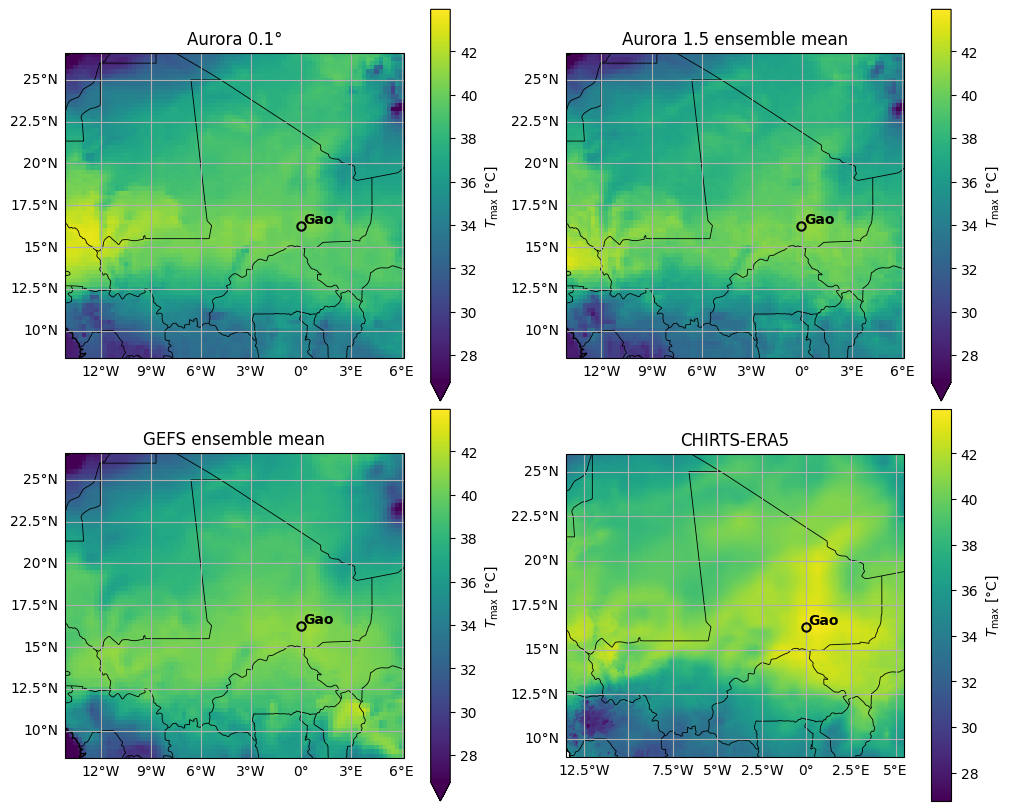

In [ ]:
vmin = float(data.tmax.min())
vmax = float(data.tmax.max())
set_label(data.aurora_t2m, r"$T_\mathrm{max}$", "°C")
set_label(data.ens_mean_t2m, r"$T_\mathrm{max}$", "°C")
set_label(data.gefs_t2m, r"$T_\mathrm{max}$", "°C")

axes = create_maps(2, 2)
data.aurora_t2m.plot(ax=axes[0], vmin=vmin, vmax=vmax)
axes[0].set_title("Aurora 0.1°")
data.ens_mean_t2m.plot(ax=axes[1], vmin=vmin, vmax=vmax)
axes[1].set_title("Aurora 1.5 ensemble mean")
data.gefs_t2m.plot(ax=axes[2], vmin=vmin, vmax=vmax)
axes[2].set_title("GEFS ensemble mean")
data.tmax.plot(ax=axes[3], vmin=vmin, vmax=vmax)
axes[3].set_title("CHIRTS-ERA5");

## Model

The model takes the fifteen coarse channels on the 0.25° grid, the lead time and the two elevation channels on the 0.05° grid, and predicts the daily maximum temperature on the 0.05° grid.
At every pixel, it gives not one number but a mean $\mu$ and a standard deviation $\sigma$, so that we also know how certain the forecast is.
It is a ConvCNP, a convolutional neural network that works on two grids.
A first CNN processes the coarse inputs on the coarse grid.
Its output is interpolated to the fine grid and combined with the elevation, and a second CNN adds the fine detail.
A final pointwise MLP uses the elevation once more to make a local correction and turns the features into $\mu$ and $\sigma$.
The inputs are normalised with the means and standard deviations from training, and the outputs are converted back to °C.

* `encode_lead_time`: encode the lead time as a sine and a cosine.
* `DepthwiseSepConv`: depthwise convolution followed by a pointwise convolution.
* `ResBlock`: pre-activation residual block.
* `CNNBackbone`: ResNet with depthwise-separable convolutions.
* `PointwiseDecoder`: per-pixel MLP from features and elevation to a mean and a standard deviation.
* `MultiscaleConvCNP`: the full model, which downscales the coarse forecasts to the fine grid.

In [ ]:
import math

import torch.nn as nn
import torch.nn.functional as F


def encode_lead_time(lead_days: torch.Tensor) -> torch.Tensor:
    """Encode lead times in days as a sine and a cosine with a period of ten days."""
    t = 2 * math.pi * lead_days.float() / 10
    return torch.stack([torch.sin(t), torch.cos(t)], dim=-1)


class DepthwiseSepConv(nn.Module):
    """Depthwise convolution followed by a pointwise convolution."""

    def __init__(self, channels: int, kernel_size: int) -> None:
        super().__init__()
        self.depthwise = nn.Conv2d(
            channels,
            channels,
            kernel_size,
            padding=kernel_size // 2,
            groups=channels,
            bias=False,
        )
        self.pointwise = nn.Conv2d(channels, channels, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.pointwise(self.depthwise(x))


class ResBlock(nn.Module):
    """Pre-activation residual block."""

    def __init__(self, channels: int, kernel_size: int) -> None:
        super().__init__()
        self.norm1 = nn.BatchNorm2d(channels)
        self.conv1 = DepthwiseSepConv(channels, kernel_size)
        self.norm2 = nn.BatchNorm2d(channels)
        self.conv2 = DepthwiseSepConv(channels, kernel_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.conv1(F.relu(self.norm1(x)))
        h = self.conv2(F.relu(self.norm2(h)))
        return x + h


class CNNBackbone(nn.Module):
    """ResNet with depthwise-separable convolutions."""

    def __init__(
        self, in_channels: int, hidden_channels: int, n_blocks: int, kernel_size: int
    ) -> None:
        super().__init__()
        self.input_proj = nn.Conv2d(in_channels, hidden_channels, 1)
        self.blocks = nn.ModuleList(
            [ResBlock(hidden_channels, kernel_size) for _ in range(n_blocks)]
        )
        self.final_norm = nn.BatchNorm2d(hidden_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.input_proj(x)
        for block in self.blocks:
            x = block(x)
        return F.relu(self.final_norm(x))


class PointwiseDecoder(nn.Module):
    """Per-pixel MLP from features and elevation to a mean and a standard deviation."""

    def __init__(
        self, feature_channels: int, elevation_channels: int, hidden: int
    ) -> None:
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Conv2d(feature_channels + elevation_channels, hidden, 1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 1),
            nn.ReLU(),
            nn.Conv2d(hidden, 2, 1),
        )

    def forward(
        self, features: torch.Tensor, elevation: torch.Tensor
    ) -> tuple[torch.Tensor, torch.Tensor]:
        out = self.mlp(torch.cat([features, elevation], dim=1))
        mu, raw_sigma = out.chunk(2, dim=1)
        return mu, F.softplus(raw_sigma) + 1e-6


class MultiscaleConvCNP(nn.Module):
    """ConvCNP that downscales coarse forecasts to a fine grid."""

    def __init__(
        self,
        hidden_channels: int = 192,
        n_resblocks: int = 8,
        kernel_size: int = 5,
        decoder_hidden: int = 128,
    ) -> None:
        super().__init__()
        self.norm_stats = torch.load(
            DATA_PATH / "norm_stats_tmax.pt", weights_only=False
        )

        # The input channels in a defined order:
        variables = ["t2m", "msl", "ws10", "z500", "q_1000", "q_925", "q_850", "q_700"]
        self.coarse_channels = (
            ["gefs_t2m"]
            + [f"aurora_{v}" for v in variables]
            + [f"ens_{s}_t2m" for s in ["mean", "median", "std", "min", "max", "iqr"]]
        )
        self.elevation_channels = ["elevation_mean", "elevation_std"]

        # Backbone CNNs:
        self.lr_cnn = CNNBackbone(
            len(self.coarse_channels) + 2,  # Lead-time encoding adds two channels.
            hidden_channels,
            n_resblocks,
            kernel_size,
        )
        self.hr_cnn = CNNBackbone(
            hidden_channels + len(self.elevation_channels),
            hidden_channels,
            n_resblocks,
            kernel_size,
        )
        self.decoder = PointwiseDecoder(
            hidden_channels,
            len(self.elevation_channels),
            decoder_hidden,
        )

    def normalise_and_stack(self, ds: xr.Dataset, names: list[str]) -> torch.Tensor:
        """Normalise and stack variables `names` of `ds` into a batched tensor."""
        stats = self.norm_stats
        channels = [(ds[n] - stats[n]["mean"]) / stats[n]["std"] for n in names]
        stacked = as_tensor(xr.concat(channels, dim="channel"))
        return stacked[None]  # Add batch dimension.

    def forward(
        self, data: xr.Dataset, lead_time_days: int
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """Predict a Gaussian at every pixel of the fine grid of `data`.

        Args:
            data: Coarse channels on the GEFS grid and elevation on the fine grid.
            lead_time_days: Lead time in days.

        Returns:
            Mean and standard deviation, both `(1, 1, H_hr, W_hr)`.
        """
        x = self.normalise_and_stack(data, self.coarse_channels)

        # Concatenate the lead-time encoding.
        lead = encode_lead_time(torch.tensor([lead_time_days]))
        lead = lead[:, :, None, None].expand(-1, -1, *x.shape[-2:])
        x = torch.cat([x, lead], dim=1)

        # Run the low-resolution CNN.
        x = self.lr_cnn(x)

        # Interpolate to the high-resolution grid, append the elevation, and run the
        # high-resolution CNN.
        elev = self.normalise_and_stack(data, self.elevation_channels)
        x = F.interpolate(x, size=elev.shape[-2:], mode="bilinear")
        x = torch.cat([x, elev], dim=1)
        x = self.hr_cnn(x)

        # Finally, run the pointwise MLP.
        mu, sigma = self.decoder(x, elev)

        # Unnormalise before returning.
        stats = self.norm_stats["target_tmax"]
        return mu * stats["std"] + stats["mean"], sigma * stats["std"]

We load the weights of the model trained with seed 42, which is one of the three models in the HeatEWS ensemble.

In [ ]:
model = MultiscaleConvCNP()
checkpoint = torch.load(
    DATA_PATH / "best_multiscale_tmax_clean_ensemble_t2m_basic_none_s42_n5000.pt",
    map_location="cpu",
    weights_only=False,
)
model.load_state_dict(checkpoint["model_state_dict"])

<All keys matched successfully>

## Prediction

We now run the model on the loaded data and visualise the predictions.
At every 0.05° pixel, the model gives a mean $\mu$, which is the forecast, and a standard deviation $\sigma$, which says how uncertain the forecast is.

In [ ]:
model = model.eval()
with torch.no_grad():
    mu, sigma = model(data, LEAD_TIME_DAYS)

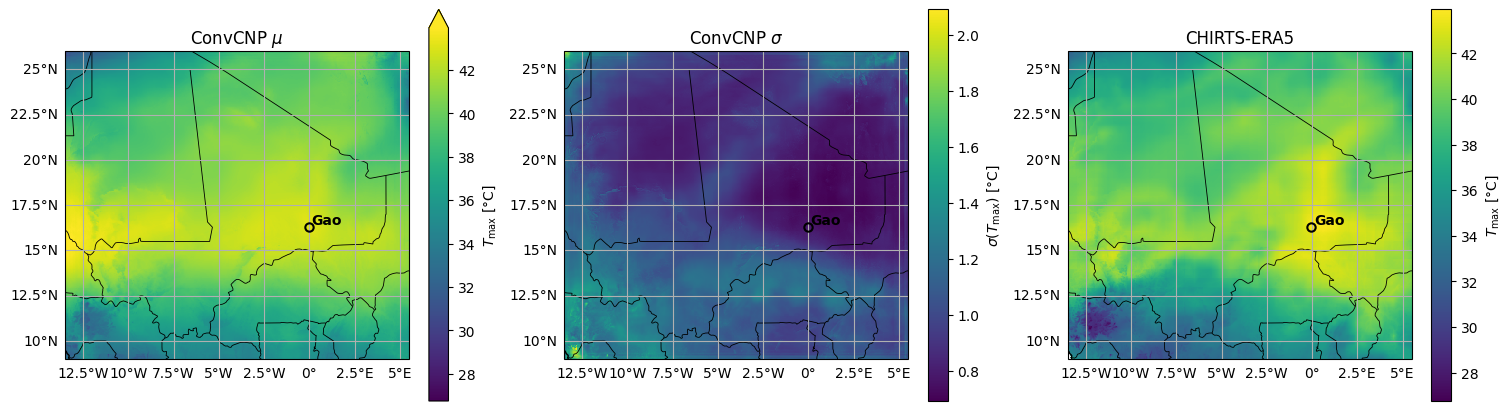

In [ ]:
pred = xr.Dataset()
# Copying `tmax` puts the predictions on the CHIRTS-ERA5 grid, with its label.
pred["mu"] = data.tmax.copy(data=mu[0, 0].numpy())
pred["sigma"] = data.tmax.copy(data=sigma[0, 0].numpy())
set_label(pred.sigma, r"$\sigma(T_\mathrm{max})$", "°C")

axes = create_maps(1, 3)
pred.mu.plot(ax=axes[0], vmin=vmin, vmax=vmax)
axes[0].set_title("ConvCNP $\\mu$")
pred.sigma.plot(ax=axes[1])
axes[1].set_title("ConvCNP $\\sigma$")
data.tmax.plot(ax=axes[2], vmin=vmin, vmax=vmax)
axes[2].set_title("CHIRTS-ERA5");

## Comparison with the raw forecasts

We check whether the ConvCNP forecast is closer to CHIRTS-ERA5 than Aurora 0.1° or GEFS.
The maps show the error, forecast minus CHIRTS-ERA5, so red means that the forecast is too warm.

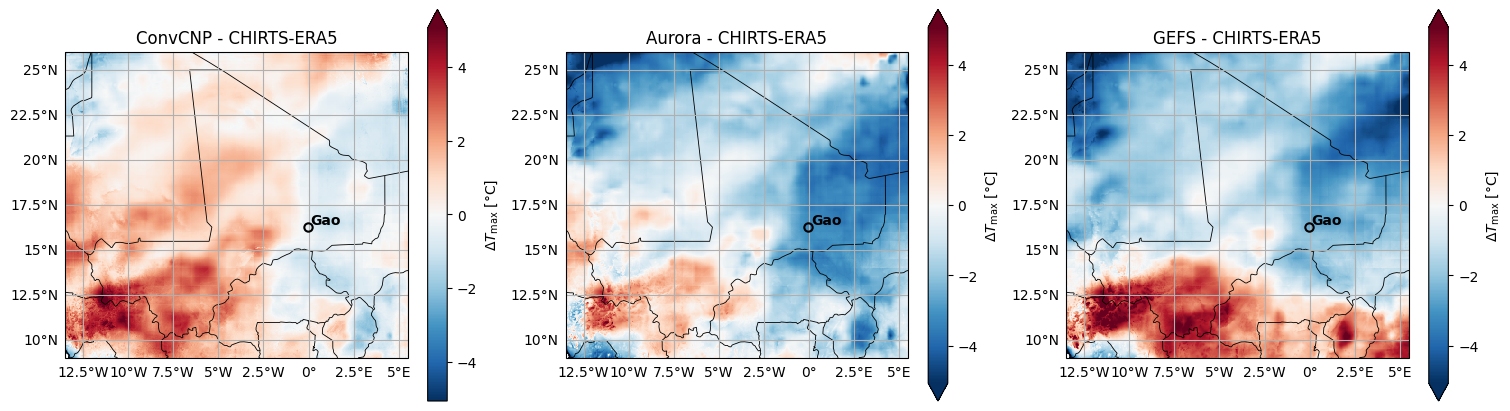

In [ ]:
# Interpolate the coarse forecasts to the CHIRTS-ERA5 grid, so that everything is on
# the same grid.
aurora_fine = data.aurora_t2m.rename(lat_gefs="lat", lon_gefs="lon")
aurora_fine = aurora_fine.interp(lat=data.lat, lon=data.lon)
gefs_fine = data.gefs_t2m.rename(lat_gefs="lat", lon_gefs="lon")
gefs_fine = gefs_fine.interp(lat=data.lat, lon=data.lon)

# Errors with respect to CHIRTS-ERA5.
convcnp_error = pred.mu - data.tmax
aurora_error = aurora_fine - data.tmax
gefs_error = gefs_fine - data.tmax
set_label(convcnp_error, r"$\Delta T_\mathrm{max}$", "°C")
set_label(aurora_error, r"$\Delta T_\mathrm{max}$", "°C")
set_label(gefs_error, r"$\Delta T_\mathrm{max}$", "°C")

# Plot the errors on a common symmetric colour scale.
limit = max(
    abs(convcnp_error).quantile(0.99),
    abs(aurora_error).quantile(0.99),
    abs(gefs_error).quantile(0.99),
)
axes = create_maps(1, 3)
convcnp_error.plot(ax=axes[0], vmin=-limit, vmax=limit, cmap="RdBu_r")
axes[0].set_title("ConvCNP - CHIRTS-ERA5")
aurora_error.plot(ax=axes[1], vmin=-limit, vmax=limit, cmap="RdBu_r")
axes[1].set_title("Aurora - CHIRTS-ERA5")
gefs_error.plot(ax=axes[2], vmin=-limit, vmax=limit, cmap="RdBu_r")
axes[2].set_title("GEFS - CHIRTS-ERA5");

### Scores

We score every forecast against CHIRTS-ERA5 with the bias (mean error), the MAE (mean absolute error) and the RMSE (root mean squared error), all in °C.
The scores are computed over the whole region and over the pixels inside Mali or Kenya only, and the last columns give the forecast, CHIRTS-ERA5 and the error at the grid cell of Gao or Lodwar.

In [ ]:
import numpy as np
import shapely
from cartopy.io import shapereader

# Grid cells inside the country, from the Natural Earth borders.
path = shapereader.natural_earth("50m", "cultural", "admin_0_countries")
records = shapereader.Reader(path).records()
geometry = next(r.geometry for r in records if r.attributes["NAME"] == COUNTRY)
inside = shapely.contains_xy(geometry, *np.meshgrid(data.lon, data.lat))
country = data.tmax.copy(data=inside)

# Bias, MAE and RMSE over the whole region and over the country, and the forecast,
# CHIRTS-ERA5 and the error at the main point.
rows = {}
for name, forecast in [
    ("ConvCNP", pred.mu),
    ("Aurora", aurora_fine),
    ("GEFS", gefs_fine),
]:
    error = forecast - data.tmax
    row = {}
    for area, e in {"whole region": error, COUNTRY: error.where(country)}.items():
        row[(area, "bias")] = float(e.mean())
        row[(area, "MAE")] = float(abs(e).mean())
        row[(area, "RMSE")] = float(np.sqrt((e**2).mean()))
    row[(MAIN_POINT, "forecast")] = float(at_point(forecast, MAIN_POINT))
    row[(MAIN_POINT, "CHIRTS-ERA5")] = float(at_point(data.tmax, MAIN_POINT))
    row[(MAIN_POINT, "error")] = float(at_point(error, MAIN_POINT))
    rows[name] = row
scores = pd.DataFrame(rows).T
scores.round(2)

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


whole region              Mali                  Gao                  
                bias   MAE  RMSE  bias   MAE  RMSE forecast CHIRTS-ERA5 error
ConvCNP         0.65  1.09  1.41  0.95  1.20  1.53    43.16       43.62 -0.45
Aurora         -1.38  1.78  2.14 -1.19  1.69  2.01    40.35       43.62 -3.27
GEFS           -0.86  2.09  2.41 -0.62  1.85  2.17    41.05       43.62 -2.57

### Keep a record of your runs

Every time the notebook runs, the next cell adds the scores of this forecast to a file, `results.csv`, and shows all the runs so far, one row per region, initialisation date and lead day.
Run the **Try it** boxes and watch the table grow: how do the errors and $\sigma$ change with the lead day, or on an extreme day?
The table shows the RMSE over Mali or Kenya and the forecast, $\sigma$ and CHIRTS-ERA5 at Gao or Lodwar; the file holds every score.
In Colab the file is in the *Files* panel on the left. Download it before you close the notebook, because it disappears when the session ends.

In [ ]:
RESULTS = Path("results.csv")

# One row for this forecast: what was run, and the scores from the table above.
row = {
    "region": REGION,
    "init_date": f"{INIT_DATE:%Y-%m-%d}",
    "lead_day": LEAD_TIME_DAYS,
    "valid_date": f"{VALID_DATE:%Y-%m-%d}",
    "point": MAIN_POINT,
    "ConvCNP sigma at point": round(float(at_point(pred.sigma, MAIN_POINT)), 2),
}
areas = {"whole region": "region", COUNTRY: "country", MAIN_POINT: "point"}
for name, values in scores.iterrows():
    for (area, metric), value in values.items():
        row[f"{name} {areas[area]} {metric}"] = round(value, 2)

# Add the row to the file, replacing an earlier run of the same forecast.
results = pd.read_csv(RESULTS) if RESULTS.exists() else pd.DataFrame()
results = pd.concat([results, pd.DataFrame([row])], ignore_index=True)
results = results.drop_duplicates(["region", "init_date", "lead_day"], keep="last")
results.to_csv(RESULTS, index=False)

# Show the main columns of every run so far.
columns = {
    "ConvCNP country RMSE": "ConvCNP RMSE in country",
    "Aurora country RMSE": "Aurora RMSE in country",
    "GEFS country RMSE": "GEFS RMSE in country",
    "ConvCNP point forecast": "ConvCNP at point",
    "ConvCNP sigma at point": "sigma at point",
    "ConvCNP point CHIRTS-ERA5": "CHIRTS-ERA5 at point",
}
shown = results[["region", "init_date", "lead_day", "valid_date", "point", *columns]]
shown.sort_values(["region", "init_date", "lead_day"]).rename(columns=columns)

,region,init_date,lead_day,valid_date,point,ConvCNP RMSE in country,Aurora RMSE in country,GEFS RMSE in country,ConvCNP at point,sigma at point,CHIRTS-ERA5 at point
0,mali,2025-05-01,3,2025-05-04,Gao,1.53,2.01,2.17,43.16,0.78,43.62


> **Try it 1: an extreme day.** In the configuration cell, set `INIT_DATE` to `2025-05-08` and `LEAD_TIME_DAYS` to `5`, so that the forecast is valid on 13 May 2025, the hottest day of the year at Gao, and run all cells again.
> Is the ConvCNP still better than Aurora and GEFS? Also at Gao?
> For Kenya, set `REGION` to `"kenya"`, `INIT_DATE` to `2025-03-10` and `LEAD_TIME_DAYS` to `5`: the Lodwar weather station measured 40.0 °C on 15 March 2025, its hottest day of the year. What does CHIRTS-ERA5 show at Lodwar, and what does that mean for the scores?

> **Try it 2: lead time.** Go back to the default date and change `LEAD_TIME_DAYS` from 3 to 6.
> Do the errors grow? Does $\sigma$ change?

### Zoom in

A closer look around Gao, or around Lodwar and Kakuma for Kenya: the coarse forecast, the ConvCNP forecast, CHIRTS-ERA5 and the elevation that the model uses to add local detail.

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


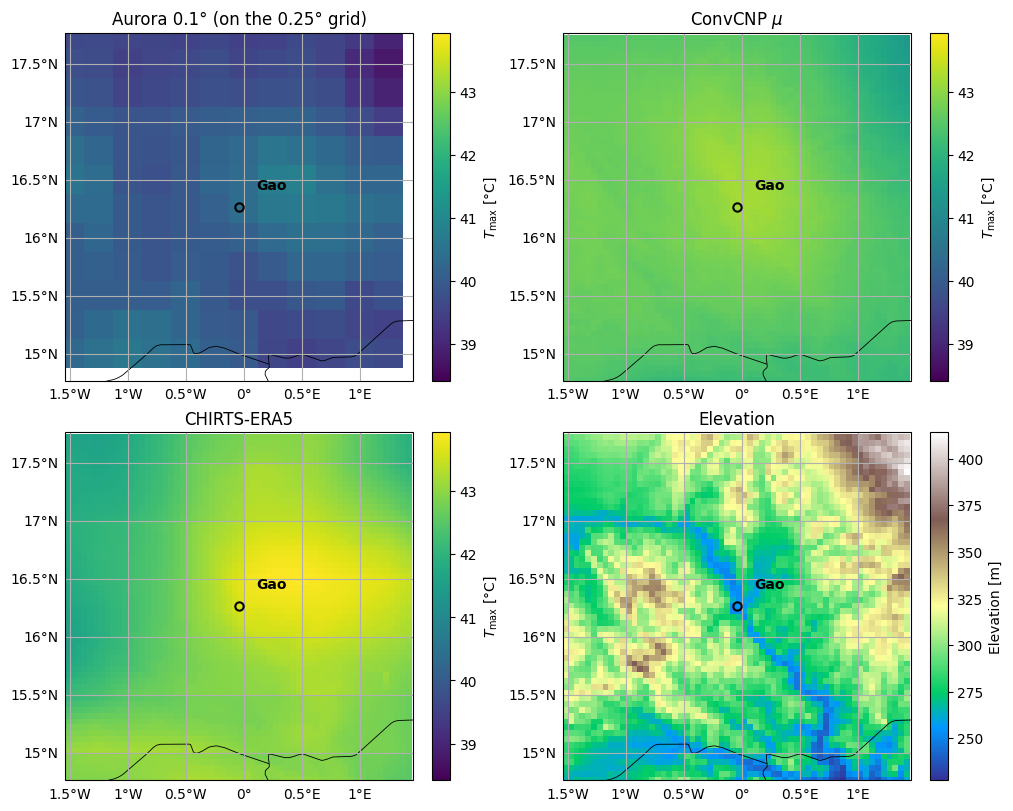

In [ ]:
HALF_WIDTH = 1.5  # Degrees around the main point

# Cut everything to a square around the main point.
lat, lon = POINTS[MAIN_POINT]
lats = slice(lat - HALF_WIDTH, lat + HALF_WIDTH)
lons = slice(lon - HALF_WIDTH, lon + HALF_WIDTH)
extent = [lons.start, lons.stop, lats.start, lats.stop]

# Use the range of CHIRTS-ERA5 over the zoomed area as the colour scale, extended
# downwards because Aurora runs cooler.
zoomed = data.tmax.sel(lat=lats, lon=lons)
zoom_vmin = float(zoomed.min()) - 3
zoom_vmax = float(zoomed.max())
axes = create_maps(2, 2)

zoomed = data.aurora_t2m.sel(lat_gefs=lats, lon_gefs=lons)
zoomed.plot(ax=axes[0], vmin=zoom_vmin, vmax=zoom_vmax)
axes[0].set_title("Aurora 0.1° (on the 0.25° grid)")
axes[0].set_extent(extent)

zoomed = pred.mu.sel(lat=lats, lon=lons)
zoomed.plot(ax=axes[1], vmin=zoom_vmin, vmax=zoom_vmax)
axes[1].set_title("ConvCNP $\\mu$")
axes[1].set_extent(extent)

zoomed = data.tmax.sel(lat=lats, lon=lons)
zoomed.plot(ax=axes[2], vmin=zoom_vmin, vmax=zoom_vmax)
axes[2].set_title("CHIRTS-ERA5")
axes[2].set_extent(extent)

zoomed = data.elevation_mean.sel(lat=lats, lon=lons)
set_label(zoomed, "Elevation", "m")
zoomed.plot(ax=axes[3], cmap="terrain")
axes[3].set_title("Elevation")
axes[3].set_extent(extent)

> **Try it 3: zoom.** Change `HALF_WIDTH`, or zoom in on Kakuma by replacing `MAIN_POINT` in the cell above.
> Where does the ConvCNP add detail that Aurora does not have? Does it follow the elevation?

> **Try it 4: the other country.** Set `REGION` to `"kenya"` and `INIT_DATE` to `2025-02-24`, then run all cells.
> Compare the scores over the whole region with those over Kenya only: why can they differ?
> (Hint: the region also contains sea, Lake Victoria and parts of neighbouring countries.)

> **Try it 5: missing data.** Set `REGION` to `"mali"` and `INIT_DATE` to `2025-04-11`, then run all cells.
> What happens? The Aurora forecast for this date was never produced, which does happen in practice.
> What would you do in an operational setting?

## Chance of extreme heat

Because the ConvCNP predicts a mean $\mu$ and a spread $\sigma$ at every pixel, we can turn the forecast into the probability that $T_\mathrm{max}$ exceeds a threshold.
This is what an early warning system needs: not "it will be 43 °C", but "there is an 80% chance of more than 42 °C".

Gao: 93% chance of more than 42 °C; CHIRTS-ERA5 shows 43.6 °C.


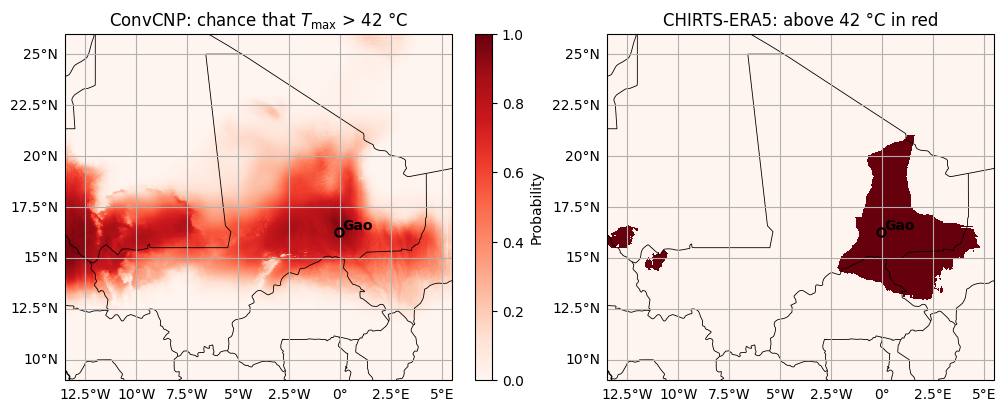

In [ ]:
from scipy.stats import norm

THRESHOLD = {"mali": 42, "kenya": 38}[REGION]  # °C

probability = 1 - norm.cdf(THRESHOLD, loc=pred.mu.values, scale=pred.sigma.values)
probability = pred.mu.copy(data=probability)
set_label(probability, "Probability")
# Keep the sea and the lakes blank rather than marking them as below the threshold.
observed = (data.tmax > THRESHOLD).where(data.tmax.notnull())

axes = create_maps(1, 2)
probability.plot(ax=axes[0], vmin=0, vmax=1, cmap="Reds")
axes[0].set_title(f"ConvCNP: chance that $T_\\mathrm{{max}}$ > {THRESHOLD} °C")
observed.plot(ax=axes[1], cmap="Reds", add_colorbar=False)
axes[1].set_title(f"CHIRTS-ERA5: above {THRESHOLD} °C in red")

chance = float(at_point(probability, MAIN_POINT))
truth = float(at_point(data.tmax, MAIN_POINT))
print(
    f"{MAIN_POINT}: {chance:.0%} chance of more than {THRESHOLD} °C; "
    f"CHIRTS-ERA5 shows {truth:.1f} °C."
)

> **Try it 6: thresholds.** Change `THRESHOLD`, for example to 40, 43 or 45 °C, and run the cell again.
> Where is the forecast confident, close to 0% or 100%, and where is it unsure?
> If you were issuing a heat warning, what probability would you act on? Would a camp manager choose the same?

## Who could be exposed?

We multiply the number of residents in every grid cell, estimated by WorldPop, by the chance that the threshold is exceeded.
Summed over the country, this gives the expected number of residents who will see a day above the threshold, and the percentage of each group who may be exposed.
It is not a prediction of illness, and both the population estimates and the probabilities are uncertain.
The first row of the table is the whole population; the second and third rows are two groups within it, children under five and people aged 65 and over.

To compare the forecast with what happened, the last two columns count the residents in the grid cells where CHIRTS-ERA5 was above the threshold on that day.
CHIRTS-ERA5 is itself an estimate, not a station measurement, and this is a single day, so treat the comparison as an example rather than a verdict.

In [ ]:
path = DATA_PATH / f"demographics/{REGION}/demographics_2025.nc"
demographics = xr.open_dataset(path)

groups = {
    "population_total": "All residents",
    "population_under5": "Children under five",
    "population_65plus": "People aged 65 and over",
}
rows = {}
for variable, label in groups.items():
    residents = demographics[variable]
    rows[label] = {
        "residents": float(residents.sum()),
        "expected above threshold": float((residents * probability).sum()),
        # `observed` is one where CHIRTS-ERA5 was above the threshold (see above).
        "above threshold in CHIRTS-ERA5": float((residents * observed).sum()),
    }
summary = pd.DataFrame(rows).T
residents_total = summary["residents"]
summary.insert(2, "expected [%]", 100 * summary["expected above threshold"] / residents_total)
summary["CHIRTS-ERA5 [%]"] = 100 * summary["above threshold in CHIRTS-ERA5"] / residents_total
summary.round().astype(int)

,residents,expected above threshold,expected [%],above threshold in CHIRTS-ERA5,CHIRTS-ERA5 [%]
All residents,24834845,5226011,21,2517305,10
Children under five,4296672,904153,21,435541,10
People aged 65 and over,589348,124042,21,59729,10


Now we use the results to find, for one group of interest, where exposure is highest.
The maps show the forecast $T_\mathrm{max}$, the number of residents in the group, and the expected number of them above the threshold.
The table lists the ten grid cells with the most residents expected above the threshold.
Choose the group with `GROUP`.

,,forecast,probability,residents,expected
lat,lon,,,,
16.275,-0.025,43.16,0.93,6184.16,5756.20
14.425,-11.425,42.81,0.75,6664.39,4986.65
14.475,-11.425,42.89,0.77,4923.75,3773.12
16.775,-3.025,42.63,0.77,3379.96,2609.13
14.425,-11.475,42.74,0.73,2401.21,1744.87
14.525,-4.075,41.94,0.48,3286.85,1569.03
15.025,-2.975,42.42,0.65,2127.84,1385.41
14.475,-11.475,42.86,0.76,1413.28,1071.28
15.925,2.375,42.31,0.66,1611.67,1061.81


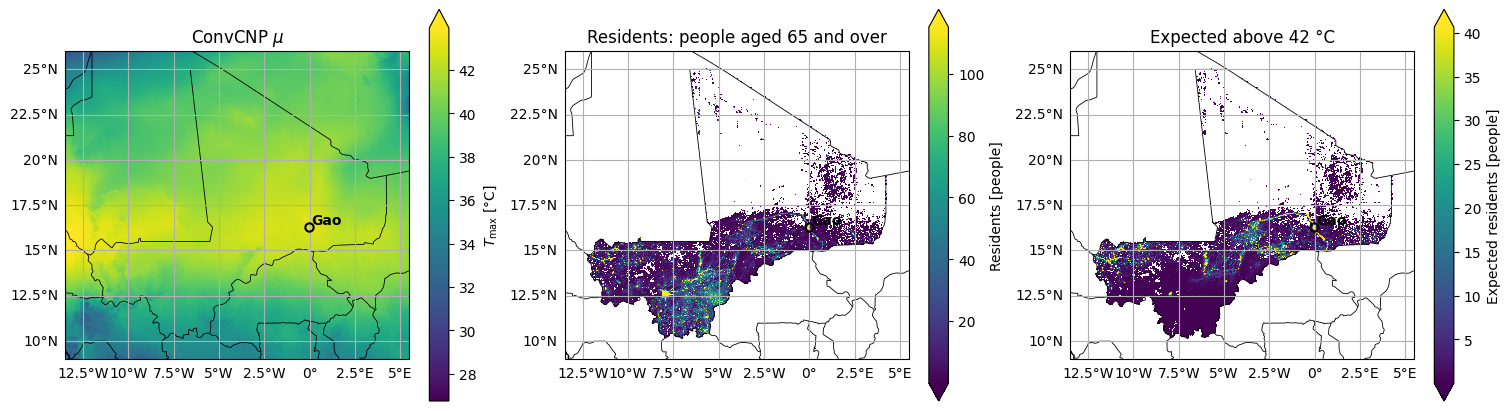

In [ ]:
GROUP = "population_65plus"

residents = demographics[GROUP]
expected = residents * probability

axes = create_maps(1, 3)
pred.mu.plot(ax=axes[0], vmin=vmin, vmax=vmax)
axes[0].set_title("ConvCNP $\\mu$")
set_label(residents, "Residents", "people")
residents.plot(ax=axes[1], robust=True)
axes[1].set_title(f"Residents: {groups[GROUP].lower()}")
set_label(expected, "Expected residents", "people")
expected.plot(ax=axes[2], robust=True)
axes[2].set_title(f"Expected above {THRESHOLD} °C")

# The ten grid cells with the most residents expected above the threshold.
cells = xr.Dataset(
    {
        "forecast": pred.mu,
        "probability": probability,
        "residents": residents,
        "expected": expected,
    }
)
cells = cells.to_dataframe().dropna().sort_values("expected", ascending=False).head(10)
cells.astype(float).round(2)

> **Try it 7: priorities.** Change `GROUP` and run the cell again.
> Do the ten cells change between children and older people? Are they the hottest cells or the most populated ones?
> Then change the threshold, the date or the lead time, and see which priorities are robust to those choices.

## Training

The model was trained with AdamW on batches of random 10° × 10° patches with random dates and lead times, minimising the Gaussian negative log-likelihood over the pixels where the target is defined.
The loop below is a simplified version of the actual training loop.
It trains a new model on one 10° × 10° patch in the south-west corner of the region, so the loss starts high.

In [ ]:
def gaussian_nll(
    mu: torch.Tensor, sigma: torch.Tensor, target: torch.Tensor
) -> torch.Tensor:
    """Average Gaussian negative log-likelihood over the defined `target` pixels."""
    mask = ~torch.isnan(target)
    z = (torch.nan_to_num(target) - mu) / sigma
    nll = 0.5 * (math.log(2 * math.pi) + 2 * torch.log(sigma) + z**2)
    return nll[mask].mean()


model = MultiscaleConvCNP()
optimiser = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-6)

lat0, lon0 = LAT_SLICE.start, LON_SLICE.start
for step in range(5):
    # Sample a random 10° by 10° patch at every step. We take a fixed here for
    # illustration.
    patch = data.sel(
        lat=slice(lat0, lat0 + 10),
        lon=slice(lon0, lon0 + 10),
        # Enlarge the grid of the coarse variables by 0.5°.
        lat_gefs=slice(lat0 - 0.5, lat0 + 10.5),
        lon_gefs=slice(lon0 - 0.5, lon0 + 10.5),
    )
    target = as_tensor(patch.tmax)[None, None]  # Add batch and channel dimensions.

    # Run model and compute loss.
    mu, sigma = model(patch, LEAD_TIME_DAYS)
    loss = gaussian_nll(mu, sigma, target)

    # Compute gradients and update the model parameters.
    optimiser.zero_grad()
    loss.backward()
    optimiser.step()

    print(f"Step {step}: loss={loss.item():.3f}")

Step 0: loss=4.076
Step 1: loss=3.374
Step 2: loss=2.956
Step 3: loss=2.677
Step 4: loss=2.498
